In [3]:
# ============================================================
# STEP 1 — VERIFY THE REQUIRED RETFOUND INPUTS
# ============================================================

import os

print("=" * 80)
print("STEP 1 — KAGGLE INPUT VERIFICATION")
print("=" * 80)

print("\nAll directories under /kaggle/input:\n")

for item in sorted(os.listdir("/kaggle/input")):
    print(" -", item)


# ------------------------------------------------------------
# Find the RETFound checkpoint
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("SEARCHING FOR RETFOUND CHECKPOINT")
print("=" * 80)

checkpoint_paths = []

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file == "best_model.pth":
            checkpoint_paths.append(
                os.path.join(root, file)
            )

if checkpoint_paths:
    for path in checkpoint_paths:
        print("FOUND:")
        print(path)
else:
    print("NOT FOUND: best_model.pth")


# ------------------------------------------------------------
# Find the RFMiD test.xlsx
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("SEARCHING FOR test.xlsx")
print("=" * 80)

xlsx_paths = []

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower() == "test.xlsx":
            xlsx_paths.append(
                os.path.join(root, file)
            )

if xlsx_paths:
    for path in xlsx_paths:
        print("FOUND:")
        print(path)
else:
    print("NOT FOUND: test.xlsx")


# ------------------------------------------------------------
# Find image files
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CHECKING FOR RETINAL IMAGES")
print("=" * 80)

image_count = 0
example_images = []

for root, dirs, files in os.walk("/kaggle/input"):

    for file in files:

        if file.lower().endswith(
            (".png", ".jpg", ".jpeg")
        ):

            image_count += 1

            if len(example_images) < 10:
                example_images.append(
                    os.path.join(root, file)
                )

print("Total image files found:", image_count)

print("\nExample image paths:")

for path in example_images:
    print(path)


print("\n" + "=" * 80)
print("STEP 1 COMPLETE")
print("=" * 80)

STEP 1 — KAGGLE INPUT VERIFICATION

All directories under /kaggle/input:

 - datasets
 - notebooks

SEARCHING FOR RETFOUND CHECKPOINT
FOUND:
/kaggle/input/datasets/rithika2006/retfound-best-model-checkpoint/best_model.pth

SEARCHING FOR test.xlsx
FOUND:
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/test.xlsx

CHECKING FOR RETINAL IMAGES
Total image files found: 3365

Example image paths:
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_140.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Training_1639.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Validation_364.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_265.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Validation_511.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Training_1522.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/

In [4]:
# ============================================================
# STEP 2 — LOAD THE EXACT RETFOUND CHECKPOINT
# ============================================================

import os
import sys
import importlib.util
import torch
import torch.nn as nn

print("=" * 80)
print("STEP 2 — LOADING RETFOUND")
print("=" * 80)

# ------------------------------------------------------------
# Exact checkpoint path confirmed in Step 1
# ------------------------------------------------------------

CHECKPOINT_PATH = (
    "/kaggle/input/datasets/"
    "rithika2006/retfound-best-model-checkpoint/"
    "best_model.pth"
)

print("\nCheckpoint:")
print(CHECKPOINT_PATH)
print("Exists:", os.path.exists(CHECKPOINT_PATH))


# ------------------------------------------------------------
# Clone RETFound repository
# ------------------------------------------------------------

RETFOUND_REPO = "/kaggle/working/RETFound_MAE"

if not os.path.exists(RETFOUND_REPO):

    print("\nCloning RETFound repository...")

    import subprocess

    subprocess.run(
        [
            "git",
            "clone",
            "https://github.com/rmaphoh/RETFound_MAE.git",
            RETFOUND_REPO
        ],
        check=True
    )

    print("✓ Repository cloned")

else:

    print("\n✓ RETFound repository already exists")


# ------------------------------------------------------------
# Import RETFound model architecture
# ------------------------------------------------------------

sys.path.insert(0, RETFOUND_REPO)

MODELS_VIT = os.path.join(
    RETFOUND_REPO,
    "models_vit.py"
)

spec = importlib.util.spec_from_file_location(
    "models_vit",
    MODELS_VIT
)

models_vit = importlib.util.module_from_spec(spec)

sys.modules["models_vit"] = models_vit

spec.loader.exec_module(models_vit)

RETFound_mae = models_vit.RETFound_mae

print("✓ RETFound_mae imported")


# ------------------------------------------------------------
# Classifier wrapper used in your XAI pipeline
# ------------------------------------------------------------

class RETFoundClassifier(nn.Module):

    def __init__(self, backbone):

        super().__init__()

        self.backbone = backbone

    def forward(self, x):

        features = self.backbone.forward_features(x)

        if features.ndim == 3 and features.shape[1] == 1:

            features = features[:, 0, :]

        logits = self.backbone.head(features)

        return logits


# ------------------------------------------------------------
# Create exact 10-class architecture
# ------------------------------------------------------------

print("\nCreating RETFound model...")

backbone = RETFound_mae(
    img_size=224,
    num_classes=10,
    global_pool=True
)

model = RETFoundClassifier(
    backbone
)

print("✓ Model architecture created")


# ------------------------------------------------------------
# Load checkpoint
# ------------------------------------------------------------

print("\nLoading checkpoint...")

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint loaded.")

print("\nCheckpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):

    print(
        "Checkpoint keys:",
        list(checkpoint.keys())[:20]
    )


# ------------------------------------------------------------
# Extract model state dictionary
# ------------------------------------------------------------

if "model_state_dict" in checkpoint:

    state = checkpoint["model_state_dict"]

elif "state_dict" in checkpoint:

    state = checkpoint["state_dict"]

else:

    state = checkpoint


# ------------------------------------------------------------
# Remove possible DataParallel prefix
# ------------------------------------------------------------

clean_state = {}

for key, value in state.items():

    if key.startswith("module."):

        key = key[len("module."):]

    clean_state[key] = value


# ------------------------------------------------------------
# Load weights
# ------------------------------------------------------------

load_result = model.load_state_dict(
    clean_state,
    strict=True
)

print("\n✓ Model weights loaded successfully")

print("Missing keys:",
      load_result.missing_keys)

print("Unexpected keys:",
      load_result.unexpected_keys)


# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

model.eval()


# ------------------------------------------------------------
# Verify model structure
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("MODEL VERIFICATION")
print("=" * 80)

print("Device:",
      device)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

print(
    "Number of Transformer blocks:",
    len(model.backbone.blocks)
)

print(
    "Embedding dimension:",
    model.backbone.embed_dim
)

print(
    "Patch embedding:",
    model.backbone.patch_embed
)

print(
    "Final Transformer block:",
    type(model.backbone.blocks[-1])
)

print("\n" + "=" * 80)
print("STEP 2 COMPLETE")
print("=" * 80)

STEP 2 — LOADING RETFOUND

Checkpoint:
/kaggle/input/datasets/rithika2006/retfound-best-model-checkpoint/best_model.pth
Exists: True

Cloning RETFound repository...


Cloning into '/kaggle/working/RETFound_MAE'...


✓ Repository cloned


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


✓ RETFound_mae imported

Creating RETFound model...
✓ Model architecture created

Loading checkpoint...
Checkpoint loaded.

Checkpoint type: <class 'dict'>
Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'scaler_state_dict', 'best_val_f1', 'best_val_auc', 'class_names']

✓ Model weights loaded successfully
Missing keys: []
Unexpected keys: []

MODEL VERIFICATION
Device: cuda
GPU: Tesla T4
Number of Transformer blocks: 24
Embedding dimension: 1024
Patch embedding: PatchEmbed(
  (proj): Conv2d(3, 1024, kernel_size=(16, 16), stride=(16, 16))
  (norm): Identity()
)
Final Transformer block: <class 'timm.models.vision_transformer.Block'>

STEP 2 COMPLETE


In [5]:
# ============================================================
# STEP 3 — LOAD ONE OFFICIAL TEST IMAGE
# ============================================================

import os
import pandas as pd
from PIL import Image
from torchvision import transforms

print("=" * 80)
print("STEP 3 — LOAD OFFICIAL TEST IMAGE")
print("=" * 80)

# ------------------------------------------------------------
# Paths confirmed in Step 1
# ------------------------------------------------------------

DATASET_ROOT = (
    "/kaggle/input/datasets/"
    "krishba/retfound-rfmid-10-diseases"
)

TEST_METADATA = (
    DATASET_ROOT +
    "/splits_Excel/test.xlsx"
)

TEST_DIR = DATASET_ROOT + "/Test"


# ------------------------------------------------------------
# Load official test metadata
# ------------------------------------------------------------

test_df = pd.read_excel(TEST_METADATA)

print("\nTest metadata shape:")
print(test_df.shape)

print("\nTest metadata columns:")
print(test_df.columns.tolist())


# ------------------------------------------------------------
# Show first few rows
# ------------------------------------------------------------

print("\nFirst 5 rows:")
display(test_df.head())


# ------------------------------------------------------------
# Find image files inside Test
# ------------------------------------------------------------

test_images = []

for root, dirs, files in os.walk(TEST_DIR):

    for file in files:

        if file.lower().endswith(
            (".png", ".jpg", ".jpeg")
        ):

            test_images.append(
                os.path.join(root, file)
            )

test_images = sorted(test_images)

print("\nNumber of test image files found:")
print(len(test_images))

print("\nFirst 10 test image paths:")

for path in test_images[:10]:
    print(path)


# ------------------------------------------------------------
# Select the first actual test image
# ------------------------------------------------------------

IMAGE_PATH = test_images[0]

print("\n" + "=" * 80)
print("SELECTED TEST IMAGE")
print("=" * 80)

print(IMAGE_PATH)


# ------------------------------------------------------------
# Load image
# ------------------------------------------------------------

image = Image.open(
    IMAGE_PATH
).convert("RGB")

print("\nOriginal image size:")
print(image.size)


# ------------------------------------------------------------
# Exact preprocessing
# ------------------------------------------------------------

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

input_tensor = transform(
    image
).unsqueeze(0).to(device)

print("\nInput tensor shape:")
print(input_tensor.shape)

print("\nInput tensor device:")
print(input_tensor.device)

print("\n" + "=" * 80)
print("STEP 3 COMPLETE")
print("=" * 80)

STEP 3 — LOAD OFFICIAL TEST IMAGE

Test metadata shape:
(402, 11)

Test metadata columns:
['Image_Key', 'DR', 'MH', 'ODC', 'TSLN', 'DN', 'ARMD', 'MYA', 'BRVO', 'ODP', 'Is_Normal']

First 5 rows:


,Image_Key,DR,MH,ODC,TSLN,DN,ARMD,MYA,BRVO,ODP,Is_Normal
0,Training_3,1,0,0,0,0,0,0,0,0,False
1,Training_11,0,1,0,0,0,1,0,0,0,False
2,Training_14,0,0,0,0,1,0,0,0,0,False
3,Training_24,0,1,0,1,0,0,0,0,0,False
4,Training_27,0,0,0,1,0,0,0,0,1,False



Number of test image files found:
507

First 10 test image paths:
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Testing_38.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Testing_458.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Testing_46.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Testing_466.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Testing_48.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Testing_52.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Testing_59.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Training_1068.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Training_11.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Training_1269.png

SELECTED TEST IMAGE
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Testi

In [6]:
# ============================================================
# STEP 4 — VERIFY IMAGE ↔ OFFICIAL TEST METADATA MAPPING
# ============================================================

import os
import glob

print("=" * 80)
print("STEP 4 — VERIFY TEST IMAGE MAPPING")
print("=" * 80)

# ------------------------------------------------------------
# Use the first official Image_Key from test.xlsx
# ------------------------------------------------------------

image_key = str(test_df.iloc[0]["Image_Key"])

print("\nOfficial test Image_Key selected:")
print(image_key)


# ------------------------------------------------------------
# Find every image in the Test directory with this Image_Key
# ------------------------------------------------------------

all_matches = []

for root, dirs, files in os.walk(TEST_DIR):

    for file in files:

        if file.lower().endswith(
            (".png", ".jpg", ".jpeg")
        ):

            filename_without_ext = os.path.splitext(file)[0]

            if filename_without_ext == image_key:

                all_matches.append(
                    os.path.join(root, file)
                )


# ------------------------------------------------------------
# Display matches
# ------------------------------------------------------------

print("\nMatching image files found:")

if all_matches:

    for path in all_matches:
        print("✓", path)

else:

    print("❌ No exact image match found")


# ------------------------------------------------------------
# Display official ground-truth labels
# ------------------------------------------------------------

label_columns = [
    "DR",
    "MH",
    "ODC",
    "TSLN",
    "DN",
    "ARMD",
    "MYA",
    "BRVO",
    "ODP",
    "Is_Normal"
]

row = test_df[
    test_df["Image_Key"].astype(str) == image_key
].iloc[0]

print("\n" + "=" * 80)
print("OFFICIAL TEST LABELS")
print("=" * 80)

for label in label_columns:

    print(
        f"{label:<12}: {row[label]}"
    )


# ------------------------------------------------------------
# Check uniqueness
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("MAPPING CHECK")
print("=" * 80)

print("Image_Key:", image_key)
print("Number of matching image files:", len(all_matches))

if len(all_matches) == 1:

    print("✓ EXACTLY ONE IMAGE MATCH")

elif len(all_matches) > 1:

    print("⚠ MULTIPLE IMAGE MATCHES")

else:

    print("❌ IMAGE NOT FOUND")


print("\n" + "=" * 80)
print("STEP 4 COMPLETE")
print("=" * 80)

STEP 4 — VERIFY TEST IMAGE MAPPING

Official test Image_Key selected:
Training_3

Matching image files found:
✓ /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/DR/Training_3.png

OFFICIAL TEST LABELS
DR          : 1
MH          : 0
ODC         : 0
TSLN        : 0
DN          : 0
ARMD        : 0
MYA         : 0
BRVO        : 0
ODP         : 0
Is_Normal   : False

MAPPING CHECK
Image_Key: Training_3
Number of matching image files: 1
✓ EXACTLY ONE IMAGE MATCH

STEP 4 COMPLETE


In [7]:
# ============================================================
# STEP 5 — VERIFY RETFOUND PREDICTION
# ============================================================

import torch
import numpy as np

print("=" * 80)
print("STEP 5 — RETFOUND PREDICTION")
print("=" * 80)

# ------------------------------------------------------------
# Use the correctly mapped official test image
# ------------------------------------------------------------

IMAGE_PATH = all_matches[0]

print("\nImage:")
print(IMAGE_PATH)


# ------------------------------------------------------------
# Load image and apply the same preprocessing
# ------------------------------------------------------------

from PIL import Image
from torchvision import transforms

image = Image.open(
    IMAGE_PATH
).convert("RGB")

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

input_tensor = transform(
    image
).unsqueeze(0).to(device)


# ------------------------------------------------------------
# Your 10 project classes
# ------------------------------------------------------------

class_names = [
    "DR",
    "MH",
    "ODC",
    "TSLN",
    "DN",
    "ARMD",
    "MYA",
    "BRVO",
    "ODP",
    "Is_Normal"
]


# ------------------------------------------------------------
# Use the thresholds from your existing final pipeline
# ------------------------------------------------------------

thresholds = {
    "DR": 0.55,
    "MH": 0.75,
    "ODC": 0.15,
    "TSLN": 0.75,
    "DN": 0.30,
    "ARMD": 0.15,
    "MYA": 0.25,
    "BRVO": 0.80,
    "ODP": 0.35,
    "Is_Normal": 0.90
}


# ------------------------------------------------------------
# Forward pass
# ------------------------------------------------------------

model.eval()

with torch.no_grad():

    logits = model(
        input_tensor
    )

probabilities = torch.sigmoid(
    logits
)[0].detach().cpu().numpy()


# ------------------------------------------------------------
# Display probabilities
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("RETFOUND OUTPUT")
print("=" * 80)

for i, class_name in enumerate(class_names):

    probability = probabilities[i]
    threshold = thresholds[class_name]

    predicted = probability >= threshold

    print(
        f"{class_name:<12} "
        f"Probability = {probability:.6f} | "
        f"Threshold = {threshold:.2f} | "
        f"Predicted = {predicted}"
    )


# ------------------------------------------------------------
# Predicted diseases
# ------------------------------------------------------------

predicted_classes = [
    class_names[i]
    for i in range(len(class_names))
    if probabilities[i] >= thresholds[class_names[i]]
]

print("\n" + "=" * 80)
print("FINAL RETFOUND PREDICTION")
print("=" * 80)

if predicted_classes:

    for disease in predicted_classes:
        print(
            f"✓ {disease} "
            f"({probabilities[class_names.index(disease)]:.6f})"
        )

else:

    print("No disease crossed its class-specific threshold.")


# ------------------------------------------------------------
# Ground truth for comparison
# ------------------------------------------------------------

official_row = test_df[
    test_df["Image_Key"].astype(str) == image_key
].iloc[0]

ground_truth = [
    class_names[i]
    for i in range(len(class_names))
    if bool(official_row[class_names[i]])
]

print("\nOfficial ground truth:")

for disease in ground_truth:
    print(f"✓ {disease}")

print("\n" + "=" * 80)
print("STEP 5 COMPLETE")
print("=" * 80)

STEP 5 — RETFOUND PREDICTION

Image:
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/DR/Training_3.png

RETFOUND OUTPUT
DR           Probability = 0.999736 | Threshold = 0.55 | Predicted = True
MH           Probability = 0.000598 | Threshold = 0.75 | Predicted = False
ODC          Probability = 0.005869 | Threshold = 0.15 | Predicted = False
TSLN         Probability = 0.000817 | Threshold = 0.75 | Predicted = False
DN           Probability = 0.000671 | Threshold = 0.30 | Predicted = False
ARMD         Probability = 0.001081 | Threshold = 0.15 | Predicted = False
MYA          Probability = 0.001571 | Threshold = 0.25 | Predicted = False
BRVO         Probability = 0.000957 | Threshold = 0.80 | Predicted = False
ODP          Probability = 0.000727 | Threshold = 0.35 | Predicted = False
Is_Normal    Probability = 0.000861 | Threshold = 0.90 | Predicted = False

FINAL RETFOUND PREDICTION
✓ DR (0.999736)

Official ground truth:
✓ DR

STEP 5 COMPLETE


STEP 6 — GENERATING EXISTING XAI

Target disease:
DR
Original DR probability: 0.99973613

Final Transformer activation shape:
torch.Size([1, 197, 1024])
Final Transformer gradient shape:
torch.Size([1, 197, 1024])

Patch activation shape:
torch.Size([1, 196, 1024])
Patch gradient shape:
torch.Size([1, 196, 1024])

Patch attribution shape:
torch.Size([196])

14 × 14 heatmap shape:
(14, 14)
Minimum attribution: 0.0
Maximum attribution: 0.00869734
Mean attribution: 0.0013457517
Number of positive patches: 87


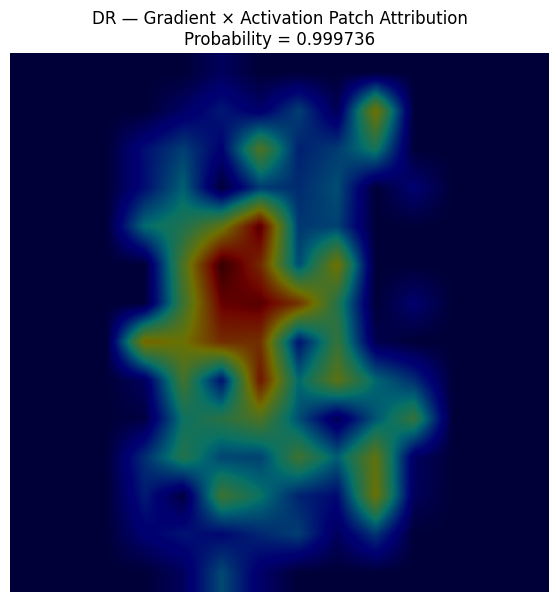


STEP 6 COMPLETE


In [8]:
# ============================================================
# STEP 6 — REPRODUCE YOUR EXISTING XAI
# Gradient × Activation Patch Attribution
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

print("=" * 80)
print("STEP 6 — GENERATING EXISTING XAI")
print("=" * 80)

# ------------------------------------------------------------
# Target class = DR
# From Step 5, DR is the predicted class
# ------------------------------------------------------------

target_class = class_names.index("DR")

print("\nTarget disease:")
print("DR")

print(
    "Original DR probability:",
    probabilities[target_class]
)


# ------------------------------------------------------------
# Storage for final Transformer activation
# ------------------------------------------------------------

xai_storage = {}


# ------------------------------------------------------------
# Hook the FINAL Transformer block
# ------------------------------------------------------------

def save_activation(module, inputs, output):

    xai_storage["activation"] = output

    # We need gradients with respect to this activation
    output.retain_grad()


hook = model.backbone.blocks[-1].register_forward_hook(
    save_activation
)


# ------------------------------------------------------------
# Forward + backward pass
# ------------------------------------------------------------

model.zero_grad(set_to_none=True)

logits = model(input_tensor)

target_logit = logits[0, target_class]

target_probability = torch.sigmoid(
    target_logit
)

target_logit.backward()


# ------------------------------------------------------------
# Remove hook
# ------------------------------------------------------------

hook.remove()


# ------------------------------------------------------------
# Retrieve activation + gradient
# ------------------------------------------------------------

activation = xai_storage["activation"]

gradient = activation.grad


print("\nFinal Transformer activation shape:")
print(activation.shape)

print("Final Transformer gradient shape:")
print(gradient.shape)


# ------------------------------------------------------------
# Remove CLS token
#
# RETFound output:
# [CLS] + 196 image patches
# ------------------------------------------------------------

patch_activation = activation[:, 1:, :]
patch_gradient = gradient[:, 1:, :]

print("\nPatch activation shape:")
print(patch_activation.shape)

print("Patch gradient shape:")
print(patch_gradient.shape)


# ------------------------------------------------------------
# Gradient × Activation
# ------------------------------------------------------------

patch_attribution = (
    patch_activation * patch_gradient
).sum(dim=-1)


# ------------------------------------------------------------
# Remove batch dimension
# ------------------------------------------------------------

patch_attribution = patch_attribution[0]


print("\nPatch attribution shape:")
print(patch_attribution.shape)


# ------------------------------------------------------------
# Positive attribution
# ------------------------------------------------------------

positive_attribution = torch.relu(
    patch_attribution
)


# ------------------------------------------------------------
# Convert 196 patches → 14 × 14
# ------------------------------------------------------------

heatmap_14 = positive_attribution.reshape(
    14,
    14
).detach().cpu().numpy()


print("\n14 × 14 heatmap shape:")
print(heatmap_14.shape)

print(
    "Minimum attribution:",
    heatmap_14.min()
)

print(
    "Maximum attribution:",
    heatmap_14.max()
)

print(
    "Mean attribution:",
    heatmap_14.mean()
)

print(
    "Number of positive patches:",
    np.sum(
        heatmap_14 > 0
    )
)


# ------------------------------------------------------------
# Normalize for visualization
# ------------------------------------------------------------

if heatmap_14.max() > 0:

    heatmap_normalized = (
        heatmap_14 /
        heatmap_14.max()
    )

else:

    heatmap_normalized = heatmap_14.copy()


# ------------------------------------------------------------
# Upscale 14 × 14 → 224 × 224
# ------------------------------------------------------------

import torch.nn.functional as F

heatmap_tensor = torch.tensor(
    heatmap_normalized,
    dtype=torch.float32
).unsqueeze(0).unsqueeze(0)

heatmap_224 = F.interpolate(
    heatmap_tensor,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)[0, 0].numpy()


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

plt.figure(figsize=(7, 7))

plt.imshow(
    image
)

plt.imshow(
    heatmap_224,
    cmap="jet",
    alpha=0.45
)

plt.axis("off")

plt.title(
    f"DR — Gradient × Activation Patch Attribution\n"
    f"Probability = {target_probability.item():.6f}"
)

plt.show()


print("\n" + "=" * 80)
print("STEP 6 COMPLETE")
print("=" * 80)

In [9]:
print("=" * 80)
print("STEP 7 — PREPARING PATCH-LEVEL FAITHFULNESS TEST")
print("=" * 80)

# Use the existing 14x14 positive attribution map from Step 6
attribution_flat = positive_attribution.detach().cpu().numpy()

# Rank patches from most important → least important
ranked_indices = np.argsort(attribution_flat)[::-1]

print("Total patches:", len(ranked_indices))
print("Top 10 patch indices:", ranked_indices[:10])
print("Top 10 attribution values:", attribution_flat[ranked_indices[:10]])

# Patch percentages that will be tested
mask_percentages = [5, 10, 20, 30, 40]

print("\nMask percentages:", mask_percentages)
print("\nSTEP 7 PREPARATION COMPLETE")

STEP 7 — PREPARING PATCH-LEVEL FAITHFULNESS TEST
Total patches: 196
Top 10 patch indices: [ 75  62  90  89 118  76 103 104  91 101]
Top 10 attribution values: [0.00869734 0.00819891 0.00809523 0.00787862 0.0074343  0.00700699
 0.00694987 0.00686246 0.00685481 0.00589793]

Mask percentages: [5, 10, 20, 30, 40]

STEP 7 PREPARATION COMPLETE


In [10]:
print("=" * 80)
print("STEP 8 — DEFINING PATCH MASKING FUNCTION")
print("=" * 80)

import torch

def mask_patches(input_tensor, patch_indices):
    """
    Replace selected 16x16 image patches with the normalized
    dataset mean (zero in normalized space).
    """
    masked = input_tensor.clone()

    for idx in patch_indices:
        row = idx // 14
        col = idx % 14

        y1 = row * 16
        y2 = (row + 1) * 16
        x1 = col * 16
        x2 = (col + 1) * 16

        masked[:, :, y1:y2, x1:x2] = 0.0

    return masked


# Verify the function using the single most important patch
test_masked = mask_patches(input_tensor, [ranked_indices[0]])

print("Original tensor shape :", tuple(input_tensor.shape))
print("Masked tensor shape   :", tuple(test_masked.shape))
print("Test patch index      :", int(ranked_indices[0]))
print("Test patch row        :", int(ranked_indices[0] // 14))
print("Test patch column     :", int(ranked_indices[0] % 14))

print("\nSTEP 8 COMPLETE")

STEP 8 — DEFINING PATCH MASKING FUNCTION
Original tensor shape : (1, 3, 224, 224)
Masked tensor shape   : (1, 3, 224, 224)
Test patch index      : 75
Test patch row        : 5
Test patch column     : 5

STEP 8 COMPLETE


In [11]:
print("=" * 80)
print("STEP 9 — TOP-ATTRIBUTION PATCH MASKING")
print("=" * 80)

model.eval()

top_results = []

for pct in mask_percentages:
    n_patches = max(1, round(196 * pct / 100))

    selected_patches = ranked_indices[:n_patches]

    masked_input = mask_patches(
        input_tensor,
        selected_patches
    )

    with torch.no_grad():
        masked_logits = model(masked_input)
        masked_probability = torch.sigmoid(masked_logits[0, target_class]).item()

    probability_drop = target_probability.item() - masked_probability

    top_results.append({
        "Masked_%": pct,
        "Patches_Masked": n_patches,
        "Original_Probability": target_probability.item(),
        "Masked_Probability": masked_probability,
        "Probability_Drop": probability_drop
    })

    print(
        f"{pct:>2}% masked "
        f"({n_patches:>3} patches) | "
        f"DR probability: {masked_probability:.6f} | "
        f"Drop: {probability_drop:.6f}"
    )

print("\nSTEP 9 COMPLETE")

STEP 9 — TOP-ATTRIBUTION PATCH MASKING
 5% masked ( 10 patches) | DR probability: 0.998304 | Drop: 0.001432
10% masked ( 20 patches) | DR probability: 0.995339 | Drop: 0.004397
20% masked ( 39 patches) | DR probability: 0.912827 | Drop: 0.086909
30% masked ( 59 patches) | DR probability: 0.007011 | Drop: 0.992725
40% masked ( 78 patches) | DR probability: 0.000327 | Drop: 0.999409

STEP 9 COMPLETE


In [12]:
print("=" * 80)
print("STEP 10 — RANDOM PATCH CONTROL")
print("=" * 80)

import numpy as np

# Fixed seed so the random control is reproducible
rng = np.random.default_rng(42)

random_results = []

for pct in mask_percentages:
    n_patches = max(1, round(196 * pct / 100))

    # Randomly select exactly the same number of patches
    random_patches = rng.choice(
        196,
        size=n_patches,
        replace=False
    )

    masked_input = mask_patches(
        input_tensor,
        random_patches
    )

    with torch.no_grad():
        masked_logits = model(masked_input)
        masked_probability = torch.sigmoid(
            masked_logits[0, target_class]
        ).item()

    probability_drop = target_probability.item() - masked_probability

    random_results.append({
        "Masked_%": pct,
        "Patches_Masked": n_patches,
        "Original_Probability": target_probability.item(),
        "Masked_Probability": masked_probability,
        "Probability_Drop": probability_drop
    })

    print(
        f"{pct:>2}% masked "
        f"({n_patches:>3} patches) | "
        f"DR probability: {masked_probability:.6f} | "
        f"Drop: {probability_drop:.6f}"
    )

print("\nSTEP 10 COMPLETE")

STEP 10 — RANDOM PATCH CONTROL
 5% masked ( 10 patches) | DR probability: 0.999587 | Drop: 0.000149
10% masked ( 20 patches) | DR probability: 0.999313 | Drop: 0.000423
20% masked ( 39 patches) | DR probability: 0.999219 | Drop: 0.000517
30% masked ( 59 patches) | DR probability: 0.994184 | Drop: 0.005552
40% masked ( 78 patches) | DR probability: 0.977560 | Drop: 0.022176

STEP 10 COMPLETE


In [13]:
print("=" * 80)
print("STEP 11 — LEAST-ATTRIBUTION PATCH CONTROL")
print("=" * 80)

least_results = []

for pct in mask_percentages:
    n_patches = max(1, round(196 * pct / 100))

    # Select the least-attributed patches
    least_patches = ranked_indices[-n_patches:]

    masked_input = mask_patches(
        input_tensor,
        least_patches
    )

    with torch.no_grad():
        masked_logits = model(masked_input)
        masked_probability = torch.sigmoid(
            masked_logits[0, target_class]
        ).item()

    probability_drop = target_probability.item() - masked_probability

    least_results.append({
        "Masked_%": pct,
        "Patches_Masked": n_patches,
        "Original_Probability": target_probability.item(),
        "Masked_Probability": masked_probability,
        "Probability_Drop": probability_drop
    })

    print(
        f"{pct:>2}% masked "
        f"({n_patches:>3} patches) | "
        f"DR probability: {masked_probability:.6f} | "
        f"Drop: {probability_drop:.6f}"
    )

print("\nSTEP 11 COMPLETE")

STEP 11 — LEAST-ATTRIBUTION PATCH CONTROL
 5% masked ( 10 patches) | DR probability: 0.999569 | Drop: 0.000167
10% masked ( 20 patches) | DR probability: 0.999362 | Drop: 0.000374
20% masked ( 39 patches) | DR probability: 0.998937 | Drop: 0.000799
30% masked ( 59 patches) | DR probability: 0.998253 | Drop: 0.001483
40% masked ( 78 patches) | DR probability: 0.996365 | Drop: 0.003371

STEP 11 COMPLETE


In [14]:
print("=" * 80)
print("STEP 12 — SELECTING MULTIPLE HELD-OUT TEST IMAGES")
print("=" * 80)

# Select the first 10 official test images from test.xlsx
evaluation_keys = test_df["Image_Key"].head(10).tolist()

print("Number of evaluation images:", len(evaluation_keys))
print("\nSelected Image_Keys:")

for i, key in enumerate(evaluation_keys, 1):
    print(f"{i:>2}. {key}")

print("\nSTEP 12 COMPLETE")

STEP 12 — SELECTING MULTIPLE HELD-OUT TEST IMAGES
Number of evaluation images: 10

Selected Image_Keys:
 1. Training_3
 2. Training_11
 3. Training_14
 4. Training_24
 5. Training_27
 6. Training_31
 7. Training_39
 8. Training_45
 9. Training_46
10. Training_51

STEP 12 COMPLETE


In [15]:
print("=" * 80)
print("STEP 13 — CHECKING MODEL PREDICTIONS")
print("=" * 80)

from pathlib import Path
from PIL import Image

# Correct RFMiD test directory
test_dir = Path(
    "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test"
)

evaluation_info = []

for key in evaluation_keys:

    # Find the exact image corresponding to this official Image_Key
    matches = list(test_dir.rglob(f"{key}.png"))

    if len(matches) == 0:
        matches = list(test_dir.rglob(f"{key}.jpg"))

    if len(matches) == 0:
        matches = list(test_dir.rglob(f"{key}.jpeg"))

    if len(matches) == 0:
        print(f"{key}: IMAGE NOT FOUND")
        continue

    image_path = matches[0]

    # Same preprocessing used in Step 5
    image = Image.open(image_path).convert("RGB")
    input_tensor_eval = transform(image).unsqueeze(0).to(device)

    # Model prediction
    with torch.no_grad():
        logits_eval = model(input_tensor_eval)
        probabilities_eval = torch.sigmoid(logits_eval)[0].cpu().numpy()

    predicted_classes = [
        class_names[i]
        for i, p in enumerate(probabilities_eval)
        if p >= thresholds[class_names[i]]
    ]

    evaluation_info.append({
        "Image_Key": key,
        "Image_Path": str(image_path),
        "Input_Tensor": input_tensor_eval,
        "Probabilities": probabilities_eval,
        "Predicted_Classes": predicted_classes
    })

    print(f"\n{key}")
    print("Predicted:", predicted_classes)

    for i, cls in enumerate(class_names):
        if probabilities_eval[i] >= thresholds[cls]:
            print(f"  {cls}: {probabilities_eval[i]:.6f}")

print("\nSTEP 13 COMPLETE")

STEP 13 — CHECKING MODEL PREDICTIONS

Training_3
Predicted: ['DR']
  DR: 0.999736

Training_11
Predicted: ['MH', 'ARMD']
  MH: 0.999459
  ARMD: 0.735815

Training_14
Predicted: ['DN']
  DN: 0.919905

Training_24
Predicted: ['MH', 'TSLN']
  MH: 0.996439
  TSLN: 0.974458

Training_27
Predicted: ['DR', 'TSLN']
  DR: 0.993741
  TSLN: 0.999141

Training_31
Predicted: ['ARMD']
  ARMD: 0.749469

Training_39
Predicted: ['DR']
  DR: 0.999702

Training_45
Predicted: ['MH']
  MH: 0.998560

Training_46
Predicted: []

Training_51
Predicted: ['DR', 'DN']
  DR: 0.831899
  DN: 0.357203

STEP 13 COMPLETE


In [16]:
print("=" * 80)
print("STEP 14 — GENERATING XAI FOR ALL PREDICTED CLASSES")
print("=" * 80)

xai_evaluations = []

for item in evaluation_info:

    key = item["Image_Key"]
    input_tensor_eval = item["Input_Tensor"]
    predicted_classes = item["Predicted_Classes"]

    if len(predicted_classes) == 0:
        continue

    for disease in predicted_classes:

        target_idx = class_names.index(disease)

        xai_storage_eval = {}

        def save_activation_eval(module, inputs, output):
            xai_storage_eval["activation"] = output
            output.retain_grad()

        hook = model.backbone.blocks[-1].register_forward_hook(
            save_activation_eval
        )

        model.zero_grad(set_to_none=True)

        logits_eval = model(input_tensor_eval)
        target_logit_eval = logits_eval[0, target_idx]
        target_probability_eval = torch.sigmoid(
            target_logit_eval
        )

        target_logit_eval.backward()

        hook.remove()

        activation_eval = xai_storage_eval["activation"]
        gradient_eval = activation_eval.grad

        # Remove CLS token
        patch_activation_eval = activation_eval[:, 1:, :]
        patch_gradient_eval = gradient_eval[:, 1:, :]

        # Gradient × Activation
        patch_attribution_eval = (
            patch_activation_eval * patch_gradient_eval
        ).sum(dim=-1)

        patch_attribution_eval = patch_attribution_eval[0]

        # Positive attribution only
        positive_attribution_eval = torch.relu(
            patch_attribution_eval
        )

        heatmap_14_eval = (
            positive_attribution_eval
            .reshape(14, 14)
            .detach()
            .cpu()
            .numpy()
        )

        xai_evaluations.append({
            "Image_Key": key,
            "Disease": disease,
            "Target_Index": target_idx,
            "Original_Probability": target_probability_eval.item(),
            "Attribution": positive_attribution_eval.detach().cpu().numpy(),
            "Heatmap_14": heatmap_14_eval,
            "Input_Tensor": input_tensor_eval
        })

        print(
            f"{key:12s} | "
            f"{disease:6s} | "
            f"Probability: {target_probability_eval.item():.6f} | "
            f"Positive patches: "
            f"{int((positive_attribution_eval > 0).sum().item())}/196"
        )

print("\nTotal XAI evaluations:", len(xai_evaluations))
print("STEP 14 COMPLETE")

STEP 14 — GENERATING XAI FOR ALL PREDICTED CLASSES
Training_3   | DR     | Probability: 0.999736 | Positive patches: 87/196
Training_11  | MH     | Probability: 0.999459 | Positive patches: 102/196
Training_11  | ARMD   | Probability: 0.735815 | Positive patches: 80/196
Training_14  | DN     | Probability: 0.919905 | Positive patches: 120/196
Training_24  | MH     | Probability: 0.996439 | Positive patches: 111/196
Training_24  | TSLN   | Probability: 0.974458 | Positive patches: 72/196
Training_27  | DR     | Probability: 0.993741 | Positive patches: 75/196
Training_27  | TSLN   | Probability: 0.999141 | Positive patches: 85/196
Training_31  | ARMD   | Probability: 0.749469 | Positive patches: 77/196
Training_39  | DR     | Probability: 0.999702 | Positive patches: 85/196
Training_45  | MH     | Probability: 0.998560 | Positive patches: 102/196
Training_51  | DR     | Probability: 0.831899 | Positive patches: 70/196
Training_51  | DN     | Probability: 0.357203 | Positive patches: 90/

In [17]:
print("=" * 80)
print("STEP 15 — TOP-ATTRIBUTION MASKING ACROSS ALL CASES")
print("=" * 80)

all_top_results = []

model.eval()

for item in xai_evaluations:

    key = item["Image_Key"]
    disease = item["Disease"]
    input_tensor_eval = item["Input_Tensor"]
    original_probability = item["Original_Probability"]

    attribution = item["Attribution"]

    # Rank patches from most important to least important
    ranked_eval = np.argsort(attribution)[::-1]

    for pct in mask_percentages:

        n_patches = max(1, round(196 * pct / 100))

        selected_patches = ranked_eval[:n_patches]

        masked_input = mask_patches(
            input_tensor_eval,
            selected_patches
        )

        with torch.no_grad():
            masked_logits = model(masked_input)
            masked_probability = torch.sigmoid(
                masked_logits[0, class_names.index(disease)]
            ).item()

        probability_drop = (
            original_probability - masked_probability
        )

        all_top_results.append({
            "Image_Key": key,
            "Disease": disease,
            "Masked_%": pct,
            "Patches_Masked": n_patches,
            "Original_Probability": original_probability,
            "Masked_Probability": masked_probability,
            "Probability_Drop": probability_drop
        })

        print(
            f"{key:12s} | "
            f"{disease:6s} | "
            f"{pct:>2}% | "
            f"Original: {original_probability:.6f} | "
            f"Masked: {masked_probability:.6f} | "
            f"Drop: {probability_drop:.6f}"
        )

print("\nTotal top-attribution evaluations:", len(all_top_results))
print("STEP 15 COMPLETE")

STEP 15 — TOP-ATTRIBUTION MASKING ACROSS ALL CASES
Training_3   | DR     |  5% | Original: 0.999736 | Masked: 0.998304 | Drop: 0.001432
Training_3   | DR     | 10% | Original: 0.999736 | Masked: 0.995339 | Drop: 0.004397
Training_3   | DR     | 20% | Original: 0.999736 | Masked: 0.912827 | Drop: 0.086909
Training_3   | DR     | 30% | Original: 0.999736 | Masked: 0.007011 | Drop: 0.992725
Training_3   | DR     | 40% | Original: 0.999736 | Masked: 0.000327 | Drop: 0.999409
Training_11  | MH     |  5% | Original: 0.999459 | Masked: 0.999821 | Drop: -0.000362
Training_11  | MH     | 10% | Original: 0.999459 | Masked: 0.999900 | Drop: -0.000441
Training_11  | MH     | 20% | Original: 0.999459 | Masked: 0.999935 | Drop: -0.000476
Training_11  | MH     | 30% | Original: 0.999459 | Masked: 0.999918 | Drop: -0.000459
Training_11  | MH     | 40% | Original: 0.999459 | Masked: 0.999898 | Drop: -0.000440
Training_11  | ARMD   |  5% | Original: 0.735815 | Masked: 0.011901 | Drop: 0.723914
Training_

In [18]:
print("=" * 80)
print("STEP 16 — RANDOM CONTROL ACROSS ALL CASES")
print("=" * 80)

all_random_results = []

rng = np.random.default_rng(42)

model.eval()

for item in xai_evaluations:

    key = item["Image_Key"]
    disease = item["Disease"]
    input_tensor_eval = item["Input_Tensor"]
    original_probability = item["Original_Probability"]

    target_idx = class_names.index(disease)

    for pct in mask_percentages:

        n_patches = max(1, round(196 * pct / 100))

        random_patches = rng.choice(
            196,
            size=n_patches,
            replace=False
        )

        masked_input = mask_patches(
            input_tensor_eval,
            random_patches
        )

        with torch.no_grad():
            masked_logits = model(masked_input)

            masked_probability = torch.sigmoid(
                masked_logits[0, target_idx]
            ).item()

        probability_drop = (
            original_probability - masked_probability
        )

        all_random_results.append({
            "Image_Key": key,
            "Disease": disease,
            "Masked_%": pct,
            "Patches_Masked": n_patches,
            "Original_Probability": original_probability,
            "Masked_Probability": masked_probability,
            "Probability_Drop": probability_drop
        })

        print(
            f"{key:12s} | "
            f"{disease:6s} | "
            f"{pct:>2}% | "
            f"Masked: {masked_probability:.6f} | "
            f"Drop: {probability_drop:.6f}"
        )

print("\nTotal random-control evaluations:", len(all_random_results))
print("STEP 16 COMPLETE")

STEP 16 — RANDOM CONTROL ACROSS ALL CASES
Training_3   | DR     |  5% | Masked: 0.999587 | Drop: 0.000149
Training_3   | DR     | 10% | Masked: 0.999313 | Drop: 0.000423
Training_3   | DR     | 20% | Masked: 0.999219 | Drop: 0.000517
Training_3   | DR     | 30% | Masked: 0.994184 | Drop: 0.005552
Training_3   | DR     | 40% | Masked: 0.977560 | Drop: 0.022176
Training_11  | MH     |  5% | Masked: 0.999814 | Drop: -0.000355
Training_11  | MH     | 10% | Masked: 0.999945 | Drop: -0.000486
Training_11  | MH     | 20% | Masked: 0.999893 | Drop: -0.000434
Training_11  | MH     | 30% | Masked: 0.999772 | Drop: -0.000313
Training_11  | MH     | 40% | Masked: 0.999794 | Drop: -0.000336
Training_11  | ARMD   |  5% | Masked: 0.368412 | Drop: 0.367404
Training_11  | ARMD   | 10% | Masked: 0.129609 | Drop: 0.606207
Training_11  | ARMD   | 20% | Masked: 0.101140 | Drop: 0.634675
Training_11  | ARMD   | 30% | Masked: 0.113281 | Drop: 0.622534
Training_11  | ARMD   | 40% | Masked: 0.107383 | Drop: 0.

In [19]:
print("=" * 80)
print("STEP 17 — LEAST-ATTRIBUTION CONTROL ACROSS ALL CASES")
print("=" * 80)

all_least_results = []

model.eval()

for item in xai_evaluations:

    key = item["Image_Key"]
    disease = item["Disease"]
    input_tensor_eval = item["Input_Tensor"]
    original_probability = item["Original_Probability"]

    target_idx = class_names.index(disease)

    attribution = item["Attribution"]

    # Rank patches from most important to least important
    ranked_eval = np.argsort(attribution)[::-1]

    for pct in mask_percentages:

        n_patches = max(1, round(196 * pct / 100))

        # Select the least-attributed patches
        least_patches = ranked_eval[-n_patches:]

        masked_input = mask_patches(
            input_tensor_eval,
            least_patches
        )

        with torch.no_grad():
            masked_logits = model(masked_input)

            masked_probability = torch.sigmoid(
                masked_logits[0, target_idx]
            ).item()

        probability_drop = (
            original_probability - masked_probability
        )

        all_least_results.append({
            "Image_Key": key,
            "Disease": disease,
            "Masked_%": pct,
            "Patches_Masked": n_patches,
            "Original_Probability": original_probability,
            "Masked_Probability": masked_probability,
            "Probability_Drop": probability_drop
        })

        print(
            f"{key:12s} | "
            f"{disease:6s} | "
            f"{pct:>2}% | "
            f"Masked: {masked_probability:.6f} | "
            f"Drop: {probability_drop:.6f}"
        )

print("\nTotal least-attribution evaluations:", len(all_least_results))
print("STEP 17 COMPLETE")

STEP 17 — LEAST-ATTRIBUTION CONTROL ACROSS ALL CASES
Training_3   | DR     |  5% | Masked: 0.999569 | Drop: 0.000167
Training_3   | DR     | 10% | Masked: 0.999362 | Drop: 0.000374
Training_3   | DR     | 20% | Masked: 0.998937 | Drop: 0.000799
Training_3   | DR     | 30% | Masked: 0.998253 | Drop: 0.001483
Training_3   | DR     | 40% | Masked: 0.996365 | Drop: 0.003371
Training_11  | MH     |  5% | Masked: 0.999819 | Drop: -0.000360
Training_11  | MH     | 10% | Masked: 0.999956 | Drop: -0.000497
Training_11  | MH     | 20% | Masked: 0.999963 | Drop: -0.000504
Training_11  | MH     | 30% | Masked: 0.999934 | Drop: -0.000476
Training_11  | MH     | 40% | Masked: 0.999923 | Drop: -0.000464
Training_11  | ARMD   |  5% | Masked: 0.196764 | Drop: 0.539051
Training_11  | ARMD   | 10% | Masked: 0.092453 | Drop: 0.643363
Training_11  | ARMD   | 20% | Masked: 0.047907 | Drop: 0.687909
Training_11  | ARMD   | 30% | Masked: 0.065653 | Drop: 0.670162
Training_11  | ARMD   | 40% | Masked: 0.114025

In [20]:
print("=" * 80)
print("STEP 18 — QUANTITATIVE FAITHFULNESS COMPARISON")
print("=" * 80)

import pandas as pd
import numpy as np

# Convert results to DataFrames
top_df = pd.DataFrame(all_top_results)
random_df = pd.DataFrame(all_random_results)
least_df = pd.DataFrame(all_least_results)

summary_rows = []

for pct in mask_percentages:

    top_values = top_df[
        top_df["Masked_%"] == pct
    ]["Probability_Drop"].values

    random_values = random_df[
        random_df["Masked_%"] == pct
    ]["Probability_Drop"].values

    least_values = least_df[
        least_df["Masked_%"] == pct
    ]["Probability_Drop"].values

    top_mean = np.mean(top_values)
    random_mean = np.mean(random_values)
    least_mean = np.mean(least_values)

    # Number of cases where Top attribution has the largest drop
    case_winners = (
        (top_values > random_values) &
        (top_values > least_values)
    )

    top_winner_rate = np.mean(case_winners)

    summary_rows.append({
        "Masked_%": pct,
        "Top_Mean_Drop": top_mean,
        "Random_Mean_Drop": random_mean,
        "Least_Mean_Drop": least_mean,
        "Top_vs_Random": top_mean - random_mean,
        "Top_vs_Least": top_mean - least_mean,
        "Top_Winner_Rate": top_winner_rate
    })

summary_df = pd.DataFrame(summary_rows)

print("\nAGGREGATE RESULTS")
print("-" * 100)

for _, row in summary_df.iterrows():

    print(
        f"{int(row['Masked_%']):>2}% | "
        f"Top: {row['Top_Mean_Drop']:+.6f} | "
        f"Random: {row['Random_Mean_Drop']:+.6f} | "
        f"Least: {row['Least_Mean_Drop']:+.6f} | "
        f"Top-Random: {row['Top_vs_Random']:+.6f} | "
        f"Top-Least: {row['Top_vs_Least']:+.6f} | "
        f"Top wins: {row['Top_Winner_Rate']*100:.1f}%"
    )

print("\nNumber of disease instances:", len(xai_evaluations))
print("Masking levels:", len(mask_percentages))

print("\nSTEP 18 COMPLETE")

STEP 18 — QUANTITATIVE FAITHFULNESS COMPARISON

AGGREGATE RESULTS
----------------------------------------------------------------------------------------------------
 5% | Top: +0.133144 | Random: +0.063264 | Least: +0.041718 | Top-Random: +0.069880 | Top-Least: +0.091426 | Top wins: 61.5%
10% | Top: +0.229621 | Random: +0.090792 | Least: +0.071672 | Top-Random: +0.138829 | Top-Least: +0.157949 | Top wins: 84.6%
20% | Top: +0.441429 | Random: +0.157949 | Least: +0.131221 | Top-Random: +0.283480 | Top-Least: +0.310208 | Top wins: 84.6%
30% | Top: +0.558553 | Random: +0.202586 | Least: +0.209823 | Top-Random: +0.355966 | Top-Least: +0.348729 | Top wins: 69.2%
40% | Top: +0.618711 | Random: +0.271107 | Least: +0.214796 | Top-Random: +0.347604 | Top-Least: +0.403915 | Top wins: 76.9%

Number of disease instances: 13
Masking levels: 5

STEP 18 COMPLETE


In [21]:
print("=" * 80)
print("STEP 19 — SELECTING A STRATIFIED TEST SUBSET")
print("=" * 80)

# Disease columns only — exclude Image_Key and Is_Normal for this evaluation
disease_columns = [
    "DR", "MH", "ODC", "TSLN", "DN",
    "ARMD", "MYA", "BRVO", "ODP"
]

# Select up to 5 official test images per disease
selected_keys = []

for disease in disease_columns:

    disease_rows = test_df[test_df[disease] == 1]

    # Take up to 5 images for this disease
    selected = disease_rows["Image_Key"].head(5).tolist()

    selected_keys.extend(selected)

    print(
        f"{disease:5s} | "
        f"Available: {len(disease_rows):3d} | "
        f"Selected: {len(selected):2d}"
    )

# Remove duplicates while preserving order
evaluation_keys_large = list(dict.fromkeys(selected_keys))

print("\nTotal unique selected images:", len(evaluation_keys_large))

print("\nSelected Image_Keys:")
for i, key in enumerate(evaluation_keys_large, 1):
    print(f"{i:>3}. {key}")

print("\nSTEP 19 COMPLETE")

STEP 19 — SELECTING A STRATIFIED TEST SUBSET
DR    | Available:  94 | Selected:  5
MH    | Available:  79 | Selected:  5
ODC   | Available:  67 | Selected:  5
TSLN  | Available:  46 | Selected:  5
DN    | Available:  35 | Selected:  5
ARMD  | Available:  26 | Selected:  5
MYA   | Available:  25 | Selected:  5
BRVO  | Available:  18 | Selected:  5
ODP   | Available:  16 | Selected:  5

Total unique selected images: 35

Selected Image_Keys:
  1. Training_3
  2. Training_39
  3. Training_71
  4. Training_86
  5. Training_105
  6. Training_11
  7. Training_24
  8. Training_45
  9. Training_46
 10. Training_73
 11. Training_31
 12. Training_67
 13. Training_171
 14. Training_184
 15. Training_185
 16. Training_27
 17. Training_165
 18. Training_14
 19. Training_51
 20. Training_124
 21. Training_135
 22. Training_377
 23. Training_419
 24. Training_488
 25. Training_564
 26. Training_628
 27. Training_750
 28. Training_683
 29. Training_734
 30. Training_871
 31. Training_982
 32. Training_

In [22]:
print("=" * 80)
print("STEP 20 — CHECKING PREDICTIONS FOR STRATIFIED SUBSET")
print("=" * 80)

large_evaluation_info = []

for key in evaluation_keys_large:

    # Find exact image
    matches = list(test_dir.rglob(f"{key}.png"))

    if len(matches) == 0:
        matches = list(test_dir.rglob(f"{key}.jpg"))

    if len(matches) == 0:
        matches = list(test_dir.rglob(f"{key}.jpeg"))

    if len(matches) == 0:
        print(f"{key}: IMAGE NOT FOUND")
        continue

    image_path = matches[0]

    # Same preprocessing as the original XAI
    image = Image.open(image_path).convert("RGB")
    input_tensor_eval = transform(image).unsqueeze(0).to(device)

    # Prediction
    with torch.no_grad():
        logits_eval = model(input_tensor_eval)
        probabilities_eval = torch.sigmoid(
            logits_eval
        )[0].cpu().numpy()

    predicted_classes = [
        class_names[i]
        for i, p in enumerate(probabilities_eval)
        if p >= thresholds[class_names[i]]
    ]

    large_evaluation_info.append({
        "Image_Key": key,
        "Image_Path": str(image_path),
        "Input_Tensor": input_tensor_eval,
        "Probabilities": probabilities_eval,
        "Predicted_Classes": predicted_classes
    })

    print(
        f"{key:12s} | "
        f"Predicted: {predicted_classes}"
    )

print("\nImages evaluated:", len(large_evaluation_info))

total_predictions = sum(
    len(x["Predicted_Classes"])
    for x in large_evaluation_info
)

print("Total predicted disease instances:", total_predictions)

print("\nSTEP 20 COMPLETE")

STEP 20 — CHECKING PREDICTIONS FOR STRATIFIED SUBSET
Training_3   | Predicted: ['DR']
Training_39  | Predicted: ['DR']
Training_71  | Predicted: ['DR']
Training_86  | Predicted: ['DR']
Training_105 | Predicted: ['DR']
Training_11  | Predicted: ['MH', 'ARMD']
Training_24  | Predicted: ['MH', 'TSLN']
Training_45  | Predicted: ['MH']
Training_46  | Predicted: []
Training_73  | Predicted: ['MH', 'ODC']
Training_31  | Predicted: ['ARMD']
Training_67  | Predicted: ['ODC']
Training_171 | Predicted: ['ODC']
Training_184 | Predicted: ['ODC', 'TSLN']
Training_185 | Predicted: ['TSLN', 'ARMD']
Training_27  | Predicted: ['DR', 'TSLN']
Training_165 | Predicted: ['MH', 'TSLN']
Training_14  | Predicted: ['DN']
Training_51  | Predicted: ['DR', 'DN']
Training_124 | Predicted: ['Is_Normal']
Training_135 | Predicted: []
Training_377 | Predicted: ['ARMD']
Training_419 | Predicted: ['MH', 'MYA']
Training_488 | Predicted: ['ODC', 'ARMD', 'MYA']
Training_564 | Predicted: ['ODC', 'ARMD', 'MYA']
Training_628 |

In [23]:
print("=" * 80)
print("STEP 21 — GENERATING XAI FOR STRATIFIED SUBSET")
print("=" * 80)

large_xai_evaluations = []

for item in large_evaluation_info:

    key = item["Image_Key"]
    input_tensor_eval = item["Input_Tensor"]
    predicted_classes = item["Predicted_Classes"]

    if len(predicted_classes) == 0:
        continue

    for disease in predicted_classes:

        target_idx = class_names.index(disease)

        xai_storage_eval = {}

        def save_activation_eval(module, inputs, output):
            xai_storage_eval["activation"] = output
            output.retain_grad()

        hook = model.backbone.blocks[-1].register_forward_hook(
            save_activation_eval
        )

        model.zero_grad(set_to_none=True)

        logits_eval = model(input_tensor_eval)

        target_logit_eval = logits_eval[0, target_idx]

        target_probability_eval = torch.sigmoid(
            target_logit_eval
        )

        target_logit_eval.backward()

        hook.remove()

        activation_eval = xai_storage_eval["activation"]
        gradient_eval = activation_eval.grad

        # Remove CLS token
        patch_activation_eval = activation_eval[:, 1:, :]
        patch_gradient_eval = gradient_eval[:, 1:, :]

        # Gradient × Activation
        patch_attribution_eval = (
            patch_activation_eval * patch_gradient_eval
        ).sum(dim=-1)

        patch_attribution_eval = patch_attribution_eval[0]

        # Keep only positive attribution
        positive_attribution_eval = torch.relu(
            patch_attribution_eval
        )

        heatmap_14_eval = (
            positive_attribution_eval
            .reshape(14, 14)
            .detach()
            .cpu()
            .numpy()
        )

        large_xai_evaluations.append({
            "Image_Key": key,
            "Disease": disease,
            "Target_Index": target_idx,
            "Original_Probability": target_probability_eval.item(),
            "Attribution": positive_attribution_eval.detach().cpu().numpy(),
            "Heatmap_14": heatmap_14_eval,
            "Input_Tensor": input_tensor_eval
        })

        print(
            f"{key:12s} | "
            f"{disease:9s} | "
            f"Probability: {target_probability_eval.item():.6f} | "
            f"Positive patches: "
            f"{int((positive_attribution_eval > 0).sum().item())}/196"
        )

print("\nTotal XAI evaluations:", len(large_xai_evaluations))
print("STEP 21 COMPLETE")

STEP 21 — GENERATING XAI FOR STRATIFIED SUBSET
Training_3   | DR        | Probability: 0.999736 | Positive patches: 87/196
Training_39  | DR        | Probability: 0.999702 | Positive patches: 85/196
Training_71  | DR        | Probability: 0.999293 | Positive patches: 89/196
Training_86  | DR        | Probability: 0.999465 | Positive patches: 89/196
Training_105 | DR        | Probability: 0.995532 | Positive patches: 73/196
Training_11  | MH        | Probability: 0.999459 | Positive patches: 102/196
Training_11  | ARMD      | Probability: 0.735815 | Positive patches: 80/196
Training_24  | MH        | Probability: 0.996439 | Positive patches: 111/196
Training_24  | TSLN      | Probability: 0.974458 | Positive patches: 72/196
Training_45  | MH        | Probability: 0.998560 | Positive patches: 102/196
Training_73  | MH        | Probability: 0.998144 | Positive patches: 100/196
Training_73  | ODC       | Probability: 0.612197 | Positive patches: 91/196
Training_31  | ARMD      | Probabilit

In [24]:
print("=" * 80)
print("STEP 22 — TOP-ATTRIBUTION MASKING FOR 52 CASES")
print("=" * 80)

large_top_results = []

model.eval()

for item in large_xai_evaluations:

    key = item["Image_Key"]
    disease = item["Disease"]
    input_tensor_eval = item["Input_Tensor"]
    original_probability = item["Original_Probability"]

    attribution = item["Attribution"]

    # Rank patches from highest to lowest attribution
    ranked_eval = np.argsort(attribution)[::-1]

    for pct in mask_percentages:

        n_patches = max(1, round(196 * pct / 100))

        selected_patches = ranked_eval[:n_patches]

        masked_input = mask_patches(
            input_tensor_eval,
            selected_patches
        )

        with torch.no_grad():
            masked_logits = model(masked_input)

            masked_probability = torch.sigmoid(
                masked_logits[0, class_names.index(disease)]
            ).item()

        probability_drop = (
            original_probability - masked_probability
        )

        large_top_results.append({
            "Image_Key": key,
            "Disease": disease,
            "Masked_%": pct,
            "Patches_Masked": n_patches,
            "Original_Probability": original_probability,
            "Masked_Probability": masked_probability,
            "Probability_Drop": probability_drop
        })

        print(
            f"{key:12s} | "
            f"{disease:9s} | "
            f"{pct:>2}% | "
            f"Drop: {probability_drop:+.6f}"
        )

print("\nTotal evaluations:", len(large_top_results))
print("Expected:", 52 * 5)

print("\nSTEP 22 COMPLETE")

STEP 22 — TOP-ATTRIBUTION MASKING FOR 52 CASES
Training_3   | DR        |  5% | Drop: +0.001432
Training_3   | DR        | 10% | Drop: +0.004397
Training_3   | DR        | 20% | Drop: +0.086909
Training_3   | DR        | 30% | Drop: +0.992725
Training_3   | DR        | 40% | Drop: +0.999409
Training_39  | DR        |  5% | Drop: +0.067787
Training_39  | DR        | 10% | Drop: +0.438836
Training_39  | DR        | 20% | Drop: +0.781298
Training_39  | DR        | 30% | Drop: +0.958254
Training_39  | DR        | 40% | Drop: +0.998959
Training_71  | DR        |  5% | Drop: +0.003381
Training_71  | DR        | 10% | Drop: +0.032220
Training_71  | DR        | 20% | Drop: +0.123315
Training_71  | DR        | 30% | Drop: +0.864376
Training_71  | DR        | 40% | Drop: +0.994968
Training_86  | DR        |  5% | Drop: +0.000678
Training_86  | DR        | 10% | Drop: +0.003366
Training_86  | DR        | 20% | Drop: +0.065503
Training_86  | DR        | 30% | Drop: +0.994595
Training_86  | DR     

In [25]:
print("=" * 80)
print("STEP 23 — RANDOM CONTROL FOR 52 CASES")
print("=" * 80)

large_random_results = []

# Fixed seed for reproducibility
rng = np.random.default_rng(42)

model.eval()

for item in large_xai_evaluations:

    key = item["Image_Key"]
    disease = item["Disease"]
    input_tensor_eval = item["Input_Tensor"]
    original_probability = item["Original_Probability"]

    target_idx = class_names.index(disease)

    for pct in mask_percentages:

        n_patches = max(1, round(196 * pct / 100))

        # Randomly select exactly the same number of patches
        random_patches = rng.choice(
            196,
            size=n_patches,
            replace=False
        )

        masked_input = mask_patches(
            input_tensor_eval,
            random_patches
        )

        with torch.no_grad():
            masked_logits = model(masked_input)

            masked_probability = torch.sigmoid(
                masked_logits[0, target_idx]
            ).item()

        probability_drop = (
            original_probability - masked_probability
        )

        large_random_results.append({
            "Image_Key": key,
            "Disease": disease,
            "Masked_%": pct,
            "Patches_Masked": n_patches,
            "Original_Probability": original_probability,
            "Masked_Probability": masked_probability,
            "Probability_Drop": probability_drop
        })

        print(
            f"{key:12s} | "
            f"{disease:9s} | "
            f"{pct:>2}% | "
            f"Drop: {probability_drop:+.6f}"
        )

print("\nTotal evaluations:", len(large_random_results))
print("Expected:", 52 * 5)

print("\nSTEP 23 COMPLETE")

STEP 23 — RANDOM CONTROL FOR 52 CASES
Training_3   | DR        |  5% | Drop: +0.000149
Training_3   | DR        | 10% | Drop: +0.000423
Training_3   | DR        | 20% | Drop: +0.000517
Training_3   | DR        | 30% | Drop: +0.005552
Training_3   | DR        | 40% | Drop: +0.022176
Training_39  | DR        |  5% | Drop: +0.000236
Training_39  | DR        | 10% | Drop: +0.049566
Training_39  | DR        | 20% | Drop: +0.001747
Training_39  | DR        | 30% | Drop: +0.032191
Training_39  | DR        | 40% | Drop: +0.979523
Training_71  | DR        |  5% | Drop: +0.000595
Training_71  | DR        | 10% | Drop: +0.002758
Training_71  | DR        | 20% | Drop: +0.013487
Training_71  | DR        | 30% | Drop: +0.013145
Training_71  | DR        | 40% | Drop: +0.024036
Training_86  | DR        |  5% | Drop: +0.000379
Training_86  | DR        | 10% | Drop: +0.000760
Training_86  | DR        | 20% | Drop: +0.173402
Training_86  | DR        | 30% | Drop: +0.006524
Training_86  | DR        | 40% 

In [26]:
print("Available keys in one XAI evaluation record:")
print(large_xai_evaluations[0].keys())

print("\nFirst record:")
for k, v in large_xai_evaluations[0].items():
    if isinstance(v, torch.Tensor):
        print(k, "-> Tensor", tuple(v.shape))
    elif isinstance(v, np.ndarray):
        print(k, "-> NumPy array", v.shape)
    else:
        print(k, "->", type(v).__name__, v)

Available keys in one XAI evaluation record:
dict_keys(['Image_Key', 'Disease', 'Target_Index', 'Original_Probability', 'Attribution', 'Heatmap_14', 'Input_Tensor'])

First record:
Image_Key -> str Training_3
Disease -> str DR
Target_Index -> int 0
Original_Probability -> float 0.9997361302375793
Attribution -> NumPy array (196,)
Heatmap_14 -> NumPy array (14, 14)
Input_Tensor -> Tensor (1, 3, 224, 224)


In [27]:
print("=" * 80)
print("STEP 24 — LEAST-ATTRIBUTION CONTROL FOR 52 CASES")
print("=" * 80)

large_least_results = []

model.eval()

for item in large_xai_evaluations:

    key = item["Image_Key"]
    disease = item["Disease"]
    input_tensor_eval = item["Input_Tensor"]
    original_probability = item["Original_Probability"]
    attribution = item["Attribution"]

    target_idx = class_names.index(disease)

    # Rank patches from least important to most important
    least_ranked_patches = np.argsort(attribution)

    for pct in mask_percentages:

        n_patches = max(1, round(196 * pct / 100))

        # Select the least-attributed patches
        least_patches = least_ranked_patches[:n_patches]

        masked_input = mask_patches(
            input_tensor_eval,
            least_patches
        )

        with torch.no_grad():
            masked_logits = model(masked_input)

            masked_probability = torch.sigmoid(
                masked_logits[0, target_idx]
            ).item()

        probability_drop = (
            original_probability - masked_probability
        )

        large_least_results.append({
            "Image_Key": key,
            "Disease": disease,
            "Masked_%": pct,
            "Patches_Masked": n_patches,
            "Original_Probability": original_probability,
            "Masked_Probability": masked_probability,
            "Probability_Drop": probability_drop
        })

        print(
            f"{key:12s} | "
            f"{disease:9s} | "
            f"{pct:>2}% | "
            f"Drop: {probability_drop:+.6f}"
        )

print("\nTotal evaluations:", len(large_least_results))
print("Expected:", 52 * 5)

print("\nSTEP 24 COMPLETE")

STEP 24 — LEAST-ATTRIBUTION CONTROL FOR 52 CASES
Training_3   | DR        |  5% | Drop: +0.000167
Training_3   | DR        | 10% | Drop: +0.000374
Training_3   | DR        | 20% | Drop: +0.000799
Training_3   | DR        | 30% | Drop: +0.001483
Training_3   | DR        | 40% | Drop: +0.003371
Training_39  | DR        |  5% | Drop: +0.000182
Training_39  | DR        | 10% | Drop: +0.000264
Training_39  | DR        | 20% | Drop: +0.000890
Training_39  | DR        | 30% | Drop: +0.002343
Training_39  | DR        | 40% | Drop: +0.005225
Training_71  | DR        |  5% | Drop: +0.000671
Training_71  | DR        | 10% | Drop: +0.001005
Training_71  | DR        | 20% | Drop: +0.006111
Training_71  | DR        | 30% | Drop: +0.012910
Training_71  | DR        | 40% | Drop: +0.014184
Training_86  | DR        |  5% | Drop: +0.000253
Training_86  | DR        | 10% | Drop: +0.000619
Training_86  | DR        | 20% | Drop: +0.000830
Training_86  | DR        | 30% | Drop: +0.001044
Training_86  | DR   

In [28]:
print("=" * 90)
print("STEP 25 — FINAL PERTURBATION-BASED XAI FAITHFULNESS ANALYSIS")
print("=" * 90)

import pandas as pd
import numpy as np

# Convert results to DataFrames
top_df = pd.DataFrame(large_top_results)
random_df = pd.DataFrame(large_random_results)
least_df = pd.DataFrame(large_least_results)

# Rename probability-drop columns
top_df = top_df.rename(columns={
    "Probability_Drop": "Top_Drop"
})

random_df = random_df.rename(columns={
    "Probability_Drop": "Random_Drop"
})

least_df = least_df.rename(columns={
    "Probability_Drop": "Least_Drop"
})

# Merge the three matched conditions
comparison_df = (
    top_df[
        ["Image_Key", "Disease", "Masked_%",
         "Patches_Masked", "Original_Probability", "Top_Drop"]
    ]
    .merge(
        random_df[
            ["Image_Key", "Disease", "Masked_%",
             "Random_Drop"]
        ],
        on=["Image_Key", "Disease", "Masked_%"],
        how="inner"
    )
    .merge(
        least_df[
            ["Image_Key", "Disease", "Masked_%",
             "Least_Drop"]
        ],
        on=["Image_Key", "Disease", "Masked_%"],
        how="inner"
    )
)

# Verify matching
print("\nMatched evaluations:", len(comparison_df))
print("Expected:", 52 * 5)

# Differences from controls
comparison_df["Top_minus_Random"] = (
    comparison_df["Top_Drop"] -
    comparison_df["Random_Drop"]
)

comparison_df["Top_minus_Least"] = (
    comparison_df["Top_Drop"] -
    comparison_df["Least_Drop"]
)

# Determine which condition gives the largest probability drop
conditions = [
    "Top_Drop",
    "Random_Drop",
    "Least_Drop"
]

comparison_df["Winning_Condition"] = (
    comparison_df[conditions]
    .idxmax(axis=1)
)

# -------------------------------------------------------------------------
# AGGREGATE BY MASKING PERCENTAGE
# -------------------------------------------------------------------------

summary_rows = []

for pct in mask_percentages:

    subset = comparison_df[
        comparison_df["Masked_%"] == pct
    ].copy()

    top_mean = subset["Top_Drop"].mean()
    random_mean = subset["Random_Drop"].mean()
    least_mean = subset["Least_Drop"].mean()

    top_wins = (
        subset["Winning_Condition"] == "Top_Drop"
    ).sum()

    total_cases = len(subset)

    summary_rows.append({
        "Masked_%": pct,
        "Top_Mean_Drop": top_mean,
        "Random_Mean_Drop": random_mean,
        "Least_Mean_Drop": least_mean,
        "Top_minus_Random": top_mean - random_mean,
        "Top_minus_Least": top_mean - least_mean,
        "Top_Wins": top_wins,
        "Total_Cases": total_cases,
        "Top_Win_%": 100 * top_wins / total_cases
    })

summary_df = pd.DataFrame(summary_rows)

print("\n" + "=" * 90)
print("AGGREGATE RESULTS")
print("=" * 90)

print(
    summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# -------------------------------------------------------------------------
# OVERALL AGGREGATE ACROSS ALL MASKING LEVELS
# -------------------------------------------------------------------------

overall_top = comparison_df["Top_Drop"].mean()
overall_random = comparison_df["Random_Drop"].mean()
overall_least = comparison_df["Least_Drop"].mean()

overall_top_wins = (
    comparison_df["Winning_Condition"] == "Top_Drop"
).sum()

overall_total = len(comparison_df)

print("\n" + "=" * 90)
print("OVERALL RESULTS — ALL 260 MATCHED EVALUATIONS")
print("=" * 90)

print(f"Top-attribution mean drop   : {overall_top:.6f}")
print(f"Random mean drop            : {overall_random:.6f}")
print(f"Least-attribution mean drop : {overall_least:.6f}")

print(
    f"Top - Random                : "
    f"{overall_top - overall_random:.6f}"
)

print(
    f"Top - Least                 : "
    f"{overall_top - overall_least:.6f}"
)

print(
    f"Top wins                    : "
    f"{overall_top_wins}/{overall_total}"
)

print(
    f"Overall Top win rate        : "
    f"{100 * overall_top_wins / overall_total:.2f}%"
)

# -------------------------------------------------------------------------
# PER-DISEASE SUMMARY
# -------------------------------------------------------------------------

disease_summary = (
    comparison_df
    .groupby("Disease")
    .agg(
        Top_Mean_Drop=("Top_Drop", "mean"),
        Random_Mean_Drop=("Random_Drop", "mean"),
        Least_Mean_Drop=("Least_Drop", "mean"),
        Top_minus_Random=("Top_minus_Random", "mean"),
        Top_minus_Least=("Top_minus_Least", "mean"),
        Evaluations=("Top_Drop", "size")
    )
    .reset_index()
)

print("\n" + "=" * 90)
print("PER-CLASS SUMMARY")
print("=" * 90)

print(
    disease_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\nSTEP 25 COMPLETE")

STEP 25 — FINAL PERTURBATION-BASED XAI FAITHFULNESS ANALYSIS

Matched evaluations: 260
Expected: 260

AGGREGATE RESULTS
 Masked_%  Top_Mean_Drop  Random_Mean_Drop  Least_Mean_Drop  Top_minus_Random  Top_minus_Least  Top_Wins  Total_Cases  Top_Win_%
        5       0.211739          0.031748         0.025167          0.179990         0.186572        41           52  78.846154
       10       0.297718          0.070205         0.015080          0.227513         0.282639        42           52  80.769231
       20       0.484820          0.134492         0.030796          0.350328         0.454023        42           52  80.769231
       30       0.647350          0.173612         0.073254          0.473739         0.574096        47           52  90.384615
       40       0.699472          0.326474         0.096717          0.372997         0.602755        44           52  84.615385

OVERALL RESULTS — ALL 260 MATCHED EVALUATIONS
Top-attribution mean drop   : 0.468220
Random mean drop    

In [29]:
print("=" * 90)
print("STEP 26 — PAIRED STATISTICAL SIGNIFICANCE TEST")
print("=" * 90)

from scipy.stats import wilcoxon

# Extract paired differences
top_random_diff = (
    comparison_df["Top_Drop"] -
    comparison_df["Random_Drop"]
)

top_least_diff = (
    comparison_df["Top_Drop"] -
    comparison_df["Least_Drop"]
)

# -------------------------------------------------------------------------
# WILCOXON SIGNED-RANK TEST
# -------------------------------------------------------------------------

stat_tr, p_tr = wilcoxon(
    comparison_df["Top_Drop"],
    comparison_df["Random_Drop"],
    alternative="greater"
)

stat_tl, p_tl = wilcoxon(
    comparison_df["Top_Drop"],
    comparison_df["Least_Drop"],
    alternative="greater"
)

print("\nTop vs Random")
print("-" * 50)
print(f"Mean difference   : {top_random_diff.mean():.6f}")
print(f"Median difference : {top_random_diff.median():.6f}")
print(f"Wilcoxon statistic: {stat_tr:.6f}")
print(f"p-value           : {p_tr:.10e}")

print("\nTop vs Least")
print("-" * 50)
print(f"Mean difference   : {top_least_diff.mean():.6f}")
print(f"Median difference : {top_least_diff.median():.6f}")
print(f"Wilcoxon statistic: {stat_tl:.6f}")
print(f"p-value           : {p_tl:.10e}")

# -------------------------------------------------------------------------
# SIMPLE SIGN CHECK
# -------------------------------------------------------------------------

top_random_positive = (top_random_diff > 0).sum()
top_least_positive = (top_least_diff > 0).sum()

print("\n" + "=" * 90)
print("PAIRED COMPARISON COUNTS")
print("=" * 90)

print(
    f"Top > Random : "
    f"{top_random_positive}/{len(top_random_diff)} "
    f"({100 * top_random_positive / len(top_random_diff):.2f}%)"
)

print(
    f"Top > Least  : "
    f"{top_least_positive}/{len(top_least_diff)} "
    f"({100 * top_least_positive / len(top_least_diff):.2f}%)"
)

print("\nSTEP 26 COMPLETE")

STEP 26 — PAIRED STATISTICAL SIGNIFICANCE TEST

Top vs Random
--------------------------------------------------
Mean difference   : 0.320914
Median difference : 0.113695
Wilcoxon statistic: 31670.000000
p-value           : 4.3662360718e-34

Top vs Least
--------------------------------------------------
Mean difference   : 0.420017
Median difference : 0.351470
Wilcoxon statistic: 32118.000000
p-value           : 4.5236255747e-36

PAIRED COMPARISON COUNTS
Top > Random : 227/260 (87.31%)
Top > Least  : 236/260 (90.77%)

STEP 26 COMPLETE


In [30]:
print("=" * 90)
print("STEP 27 — CASE-LEVEL PAIRED STATISTICAL TEST")
print("=" * 90)

import pandas as pd
import numpy as np
from scipy.stats import wilcoxon

# comparison_df should already contain the 260 matched evaluations
# from Step 25 / Step 26.

# -------------------------------------------------------------------------
# Aggregate the five masking levels for each predicted class instance
# -------------------------------------------------------------------------

case_level_df = (
    comparison_df
    .groupby(["Image_Key", "Disease"], as_index=False)
    .agg(
        Top_Mean_Drop=("Top_Drop", "mean"),
        Random_Mean_Drop=("Random_Drop", "mean"),
        Least_Mean_Drop=("Least_Drop", "mean")
    )
)

print("\nNumber of predicted class instances:", len(case_level_df))
print("Expected:", 52)

# -------------------------------------------------------------------------
# Paired differences across the 52 class instances
# -------------------------------------------------------------------------

top_random_case_diff = (
    case_level_df["Top_Mean_Drop"] -
    case_level_df["Random_Mean_Drop"]
)

top_least_case_diff = (
    case_level_df["Top_Mean_Drop"] -
    case_level_df["Least_Mean_Drop"]
)

# -------------------------------------------------------------------------
# Wilcoxon signed-rank tests
# -------------------------------------------------------------------------

stat_tr, p_tr = wilcoxon(
    case_level_df["Top_Mean_Drop"],
    case_level_df["Random_Mean_Drop"],
    alternative="greater"
)

stat_tl, p_tl = wilcoxon(
    case_level_df["Top_Mean_Drop"],
    case_level_df["Least_Mean_Drop"],
    alternative="greater"
)

# -------------------------------------------------------------------------
# Results
# -------------------------------------------------------------------------

print("\n" + "=" * 90)
print("TOP vs RANDOM — CASE LEVEL")
print("=" * 90)

print(f"Mean difference   : {top_random_case_diff.mean():.6f}")
print(f"Median difference : {top_random_case_diff.median():.6f}")
print(f"Wilcoxon statistic: {stat_tr:.6f}")
print(f"p-value           : {p_tr:.10e}")

print("\n" + "=" * 90)
print("TOP vs LEAST — CASE LEVEL")
print("=" * 90)

print(f"Mean difference   : {top_least_case_diff.mean():.6f}")
print(f"Median difference : {top_least_case_diff.median():.6f}")
print(f"Wilcoxon statistic: {stat_tl:.6f}")
print(f"p-value           : {p_tl:.10e}")

# -------------------------------------------------------------------------
# Directional consistency
# -------------------------------------------------------------------------

top_random_positive = (top_random_case_diff > 0).sum()
top_least_positive = (top_least_case_diff > 0).sum()

print("\n" + "=" * 90)
print("CASE-LEVEL DIRECTIONAL COMPARISON")
print("=" * 90)

print(
    f"Top > Random : "
    f"{top_random_positive}/52 "
    f"({100 * top_random_positive / 52:.2f}%)"
)

print(
    f"Top > Least  : "
    f"{top_least_positive}/52 "
    f"({100 * top_least_positive / 52:.2f}%)"
)

print("\nSTEP 27 COMPLETE")

STEP 27 — CASE-LEVEL PAIRED STATISTICAL TEST

Number of predicted class instances: 52
Expected: 52

TOP vs RANDOM — CASE LEVEL
Mean difference   : 0.320914
Median difference : 0.359914
Wilcoxon statistic: 1345.000000
p-value           : 1.1565542294e-09

TOP vs LEAST — CASE LEVEL
Mean difference   : 0.420017
Median difference : 0.475263
Wilcoxon statistic: 1333.000000
p-value           : 2.2476354105e-09

CASE-LEVEL DIRECTIONAL COMPARISON
Top > Random : 47/52 (90.38%)
Top > Least  : 47/52 (90.38%)

STEP 27 COMPLETE


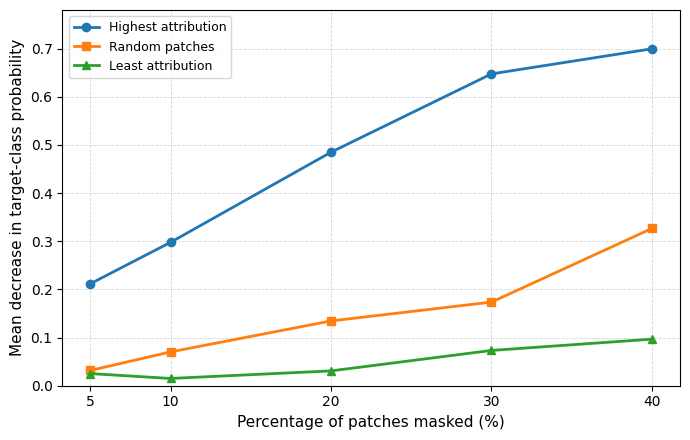

In [31]:
import matplotlib.pyplot as plt
import numpy as np

# Exact Step 25 results
mask_percentages = np.array([5, 10, 20, 30, 40])

highest_attribution = np.array([
    0.211739,
    0.297718,
    0.484820,
    0.647350,
    0.699472
])

random_patches = np.array([
    0.031748,
    0.070205,
    0.134492,
    0.173612,
    0.326474
])

least_attribution = np.array([
    0.025167,
    0.015080,
    0.030796,
    0.073254,
    0.096717
])

plt.figure(figsize=(7, 4.5))

plt.plot(
    mask_percentages,
    highest_attribution,
    marker='o',
    linewidth=2,
    label='Highest attribution'
)

plt.plot(
    mask_percentages,
    random_patches,
    marker='s',
    linewidth=2,
    label='Random patches'
)

plt.plot(
    mask_percentages,
    least_attribution,
    marker='^',
    linewidth=2,
    label='Least attribution'
)

plt.xlabel('Percentage of patches masked (%)', fontsize=11)
plt.ylabel('Mean decrease in target-class probability', fontsize=11)

plt.xticks(mask_percentages)
plt.ylim(0, 0.78)

plt.grid(True, linestyle='--', linewidth=0.6, alpha=0.5)
plt.legend(frameon=True, fontsize=9)

plt.tight_layout()

# Save high-resolution version for IEEE paper
plt.savefig(
    'XAI_Perturbation_Faithfulness.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()